In [2]:
# Terminal
# !where pip
# !where python
%pip install seaborn

Note: you may need to restart the kernel to use updated packages.


In [3]:
import pandas as pd
import matplotlib.pyplot as plt

import seaborn as sns


In [4]:
data_train = pd.read_csv('Dataset/train.csv')
data_test = pd.read_csv('Dataset/test.csv')

Performing EDA.

In [5]:
# Listing all the columns in the datasets

data_train.info()

<class 'pandas.DataFrame'>
RangeIndex: 57477 entries, 0 to 57476
Data columns (total 9 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   id              57477 non-null  int64
 1   model_a         57477 non-null  str  
 2   model_b         57477 non-null  str  
 3   prompt          57477 non-null  str  
 4   response_a      57477 non-null  str  
 5   response_b      57477 non-null  str  
 6   winner_model_a  57477 non-null  int64
 7   winner_model_b  57477 non-null  int64
 8   winner_tie      57477 non-null  int64
dtypes: int64(4), str(5)
memory usage: 3.9 MB


In [6]:
# Shape of the datasets
print('Training data shape:', data_train.shape)
print('Test data shape:', data_test.shape)

Training data shape: (57477, 9)
Test data shape: (3, 4)


In [7]:
# Checking for missing values in the datasets
train_missing = data_train.isnull().sum()
test_missing = data_test.isnull().sum()

print('Missing values in training data:', train_missing.sum())
print('Missing values in test data:', test_missing.sum())

Missing values in training data: 0
Missing values in test data: 0


In [8]:
# Checking for recurring models in the data

print('Total distinct models in training data by model:', 
      data_train['model_a'].value_counts().sum(), data_train['model_b'].value_counts().sum())
print('\n')

print('Distinct models in training and testing data by model:')
print('Model A and B:', data_train['model_a'].nunique(), data_train['model_b'].nunique())

print('\n')

print('Recurring models in training data by model:')
print('Model A:', (data_train['model_a'].value_counts().sum())-data_train['model_a'].nunique())
print('Model B:', (data_train['model_b'].value_counts().sum())-data_train['model_b'].nunique())


Total distinct models in training data by model: 57477 57477


Distinct models in training and testing data by model:
Model A and B: 64 64


Recurring models in training data by model:
Model A: 57413
Model B: 57413


Design Failure of extracting unique models

In [ ]:
# Extracting the unique models from the training data
# unique_models_a = data_train['model_a'].unique()
# unique_models_b = data_train['model_b'].unique()

# # print('Are models in a and b are same:', set(unique_models_a) == set(unique_models_b))
# # print('\n')

# # print('Unique models in training data by model:')
# # unqiue_models = set(unique_models_a).union(set(unique_models_b))

# # unique_models = list(unqiue_models)

# unique_models = pd.concat([data_train['model_a'], data_train['model_b']]).unique()

# print(unique_models)


In [ ]:
# Creating a mini dataframe for unique models with respect to their win, lose and tie counts.

# unique_models_distribution = pd.DataFrame(columns=['model', 'win_count', 'lose_count', 'tie_count'])

# unique_models_distribution['model'] = unique_models

# for model in unique_models:
#     win_count = data_train[data_train['model_a'] == model]['winner_model_a'].sum() + data_train[data_train['model_b'] == model]['winner_model_b'].sum()
#     lose_count = data_train[data_train['model_a'] == model]['winner_model_b'].sum() + data_train[data_train['model_b'] == model]['winner_model_a'].sum()
#     tie_count = data_train[data_train['model_a'] == model]['winner_tie'].sum() + data_train[data_train['model_b'] == model]['winner_tie'].sum()
#     unique_models_distribution.loc[unique_models_distribution['model'] == model, 'win_count'] = win_count
#     unique_models_distribution.loc[unique_models_distribution['model'] == model, 'lose_count'] = lose_count
#     unique_models_distribution.loc[unique_models_distribution['model'] == model, 'tie_count'] = tie_count

# print('Unique models distribution in training data:')
# print(unique_models_distribution)



In [ ]:
# # Checking the proportions of win, lose and tie in the training data
# print('Distribution of target variable in training data:')

# win_a = data_train['winner_model_a'].sum()
# win_b = data_train['winner_model_b'].sum()
# tie = data_train['winner_tie'].sum()

# print('Proportion of wins for Model A:', win_a)
# print('Proportion of wins for Model B:', win_b)
# print('Proportion of ties:', tie)


# target_distribution = data_train[['winner_model_a', 'winner_model_b', 'winner_tie']].value_counts(normalize=True)
# print(target_distribution)



In [26]:
# # Calculating the probabilities of winning, losing, and tying for each model based on the training data.

# counts = plot_data[['win_count', 'lose_count', 'tie_count']]
# probabilities = counts.div(counts.sum(axis=1), axis=0)


# sample_ids = test_model_samples.iloc[:, 0]
# sample_models = test_model_samples.iloc[:, 1]


# results = pd.DataFrame({
#     'id': sample_ids.to_numpy().astype('int64'),
#     'winner_model_a': sample_models.map(probabilities['win_count']).to_numpy(),
#     'winner_model_b': sample_models.map(probabilities['lose_count']).to_numpy(),
#     'winner_tie': sample_models.map(probabilities['tie_count']).to_numpy()
# })


# print('Sample submission results:')
# print(results.head())

In [ ]:
# # Getting the models using Id from the test data

# unique_models_with_id = pd.DataFrame(unique_models, columns=['id','model'])


# # test_model_samples = data_test[['id']].merge(unique_models, how='cross')
# # test_model_samples = pd.concat([data_test[['id']], unique_models], axis=1, ignore_index=True)
# # test_model_samples = test_model_samples[0].astype('int64')
# # test_model_samples

Broken plot as the unique models were logically broken

In [ ]:
# Plotting the unique model distribution wrt to win, lose and tie in train data.
# a = data_train.groupby('model_a').agg(  
#     win_count=('winner_model_a', 'sum'),
#     lose_count=('winner_model_b', 'sum'),
#     tie_count=('winner_tie', 'sum')
# )
# b = data_train.groupby('model_b').agg(
#     win_count=('winner_model_b', 'sum'),
#     lose_count=('winner_model_a', 'sum'),
#     tie_count=('winner_tie', 'sum')
# )

# plot_data = side_a.join(side_b, how='outer').astype(int)
# plot_data.index.name = 'model'
# plot_data = plot_data.loc[
#     plot_data.sum(axis=1).sort_values(ascending=False).index
# ]

# fig, ax = plt.subplots(figsize=(10, 20))
# sns.heatmap(
#     plot_data,
#     annot=True,
#     fmt=',d',
#     cmap='YlGnBu',
#     linewidths=0.5,
#     cbar_kws={'label': 'Count'},
#     ax=ax
# )

# ax.set_title('Win, Loss, and Tie Counts by Model')
# ax.set_xlabel('Outcome')
# ax.set_ylabel('Model')
# plt.tight_layout()
# plt.show()

Re-implementing unique models by aggregating them.

In [22]:
side_a = data_train.groupby('model_a').agg(
    a_responses=('id', 'count'),
    a_wins=('winner_model_a', 'sum'),
    a_losses=('winner_model_b', 'sum'),
    a_ties=('winner_tie', 'sum'),
)

side_b = data_train.groupby('model_b').agg(
    b_responses=('id', 'count'),
    b_wins=('winner_model_b', 'sum'),
    b_losses=('winner_model_a', 'sum'),
    b_ties=('winner_tie', 'sum'),
)

unique_models = side_a.join(side_b, how='outer').astype(int)
unique_models.index.name = 'model'

unique_models['combined_both_responses'] = unique_models['a_responses'] + unique_models['b_responses']
unique_models['wins']   = unique_models['a_wins']   + unique_models['b_wins']
unique_models['losses'] = unique_models['a_losses'] + unique_models['b_losses']
unique_models['ties']   = unique_models['a_ties']   + unique_models['b_ties']
unique_models['win_rate'] = unique_models['wins'] / unique_models['combined_both_responses']
unique_models['a_win_rate'] = unique_models['a_wins'] / unique_models['a_responses']
unique_models['b_win_rate'] = unique_models['b_wins'] / unique_models['b_responses']

dist = unique_models.reset_index()

unique_models


,a_responses,a_wins,a_losses,a_ties,b_responses,b_wins,b_losses,b_ties,combined_both_responses,wins,losses,ties,win_rate,a_win_rate,b_win_rate
model,,,,,,,,,,,,,,,
RWKV-4-Raven-14B,588,146,269,173,570,119,265,186,1158,265,534,359,0.228843,0.248299,0.208772
alpaca-13b,709,180,307,222,694,176,319,199,1403,356,626,421,0.253742,0.253879,0.253602
chatglm-6b,612,106,304,202,649,111,305,233,1261,217,609,435,0.172086,0.173203,0.171032
chatglm2-6b,283,35,161,87,281,38,159,84,564,73,320,171,0.129433,0.123675,0.135231
chatglm3-6b,503,84,270,149,486,73,268,145,989,157,538,294,0.158746,0.166998,0.150206
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
wizardlm-13b,798,275,242,281,782,297,241,244,1580,572,483,525,0.362025,0.344612,0.379795
wizardlm-70b,800,272,267,261,844,316,267,261,1644,588,534,522,0.357664,0.340000,0.374408
yi-34b-chat,696,237,228,231,751,294,214,243,1447,531,442,474,0.366966,0.340517,0.391478


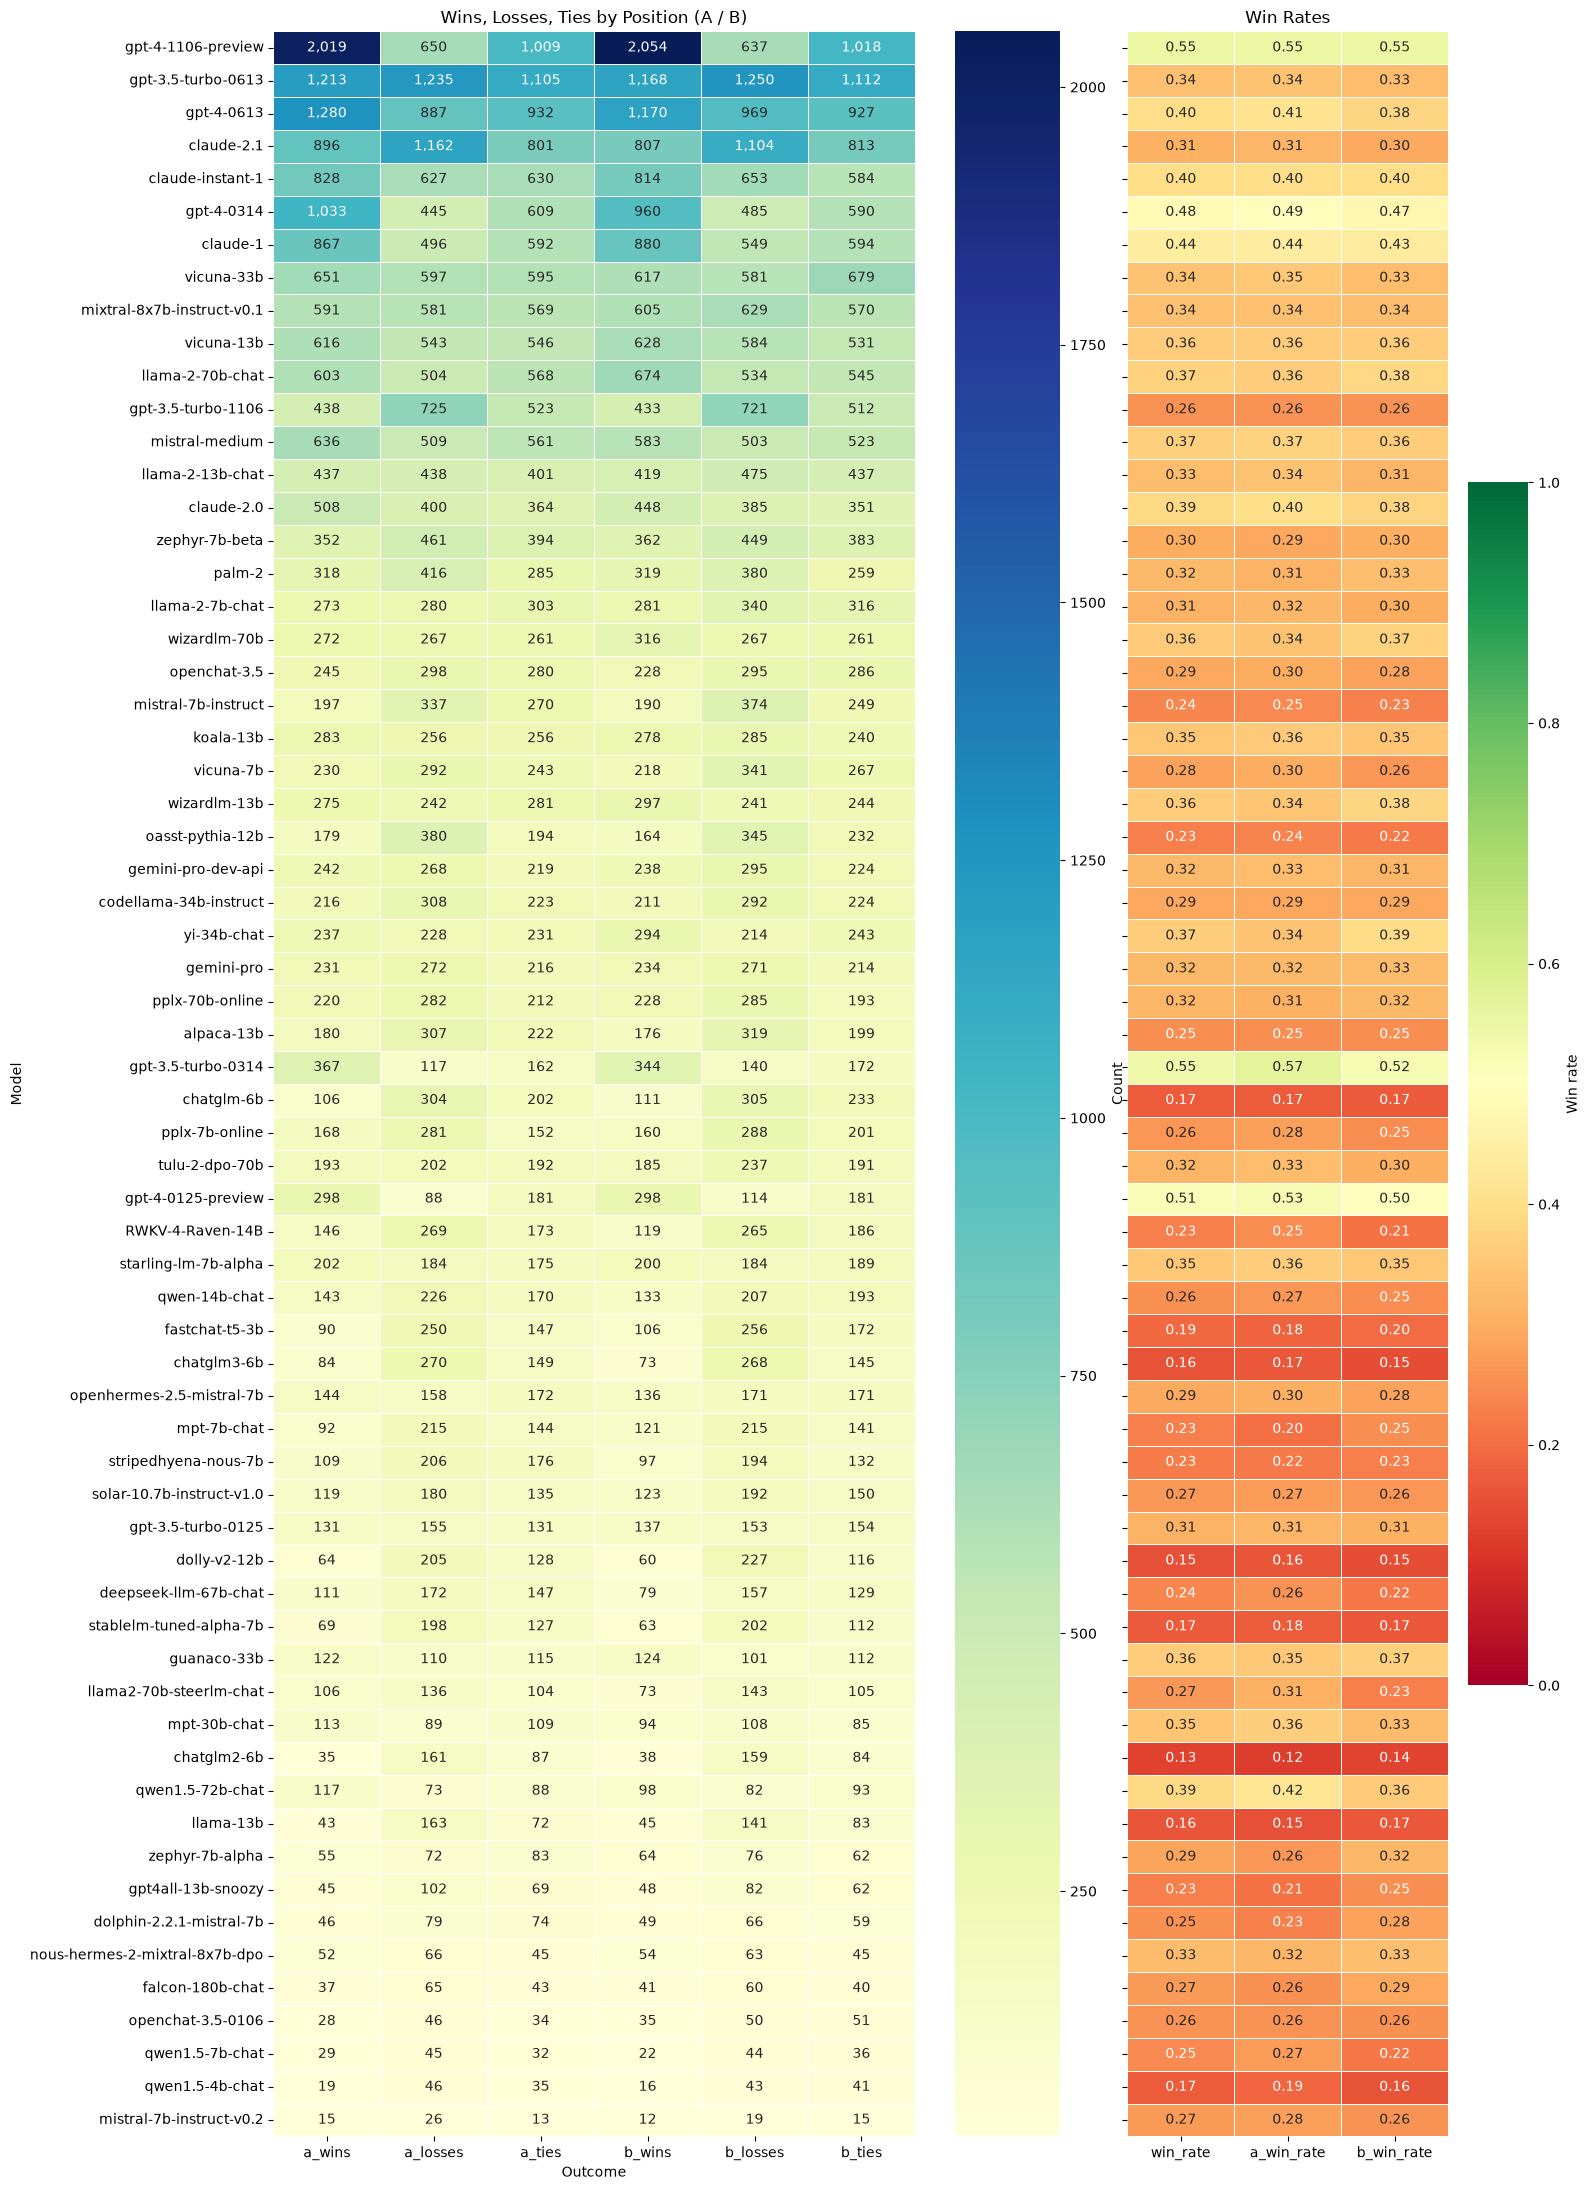

In [23]:
# Potting the unique models based on their distribution.

count_cols = ['a_wins', 'a_losses', 'a_ties', 'b_wins', 'b_losses', 'b_ties']
rate_cols  = ['win_rate', 'a_win_rate', 'b_win_rate']

# Sort by total games, so the busiest models are on top
order = unique_models['combined_both_responses'].sort_values(ascending=False).index

counts = unique_models.loc[order, count_cols]
rates  = unique_models.loc[order, rate_cols]

fig, (ax1, ax2) = plt.subplots(
    1, 2, figsize=(16, 22),
    gridspec_kw={'width_ratios': [2, 1]}
)

sns.heatmap(counts, annot=True, fmt=',d', cmap='YlGnBu',
            linewidths=0.5, cbar_kws={'label': 'Count'}, ax=ax1)
ax1.set_title('Wins, Losses, Ties by Position (A / B)')
ax1.set_xlabel('Outcome')
ax1.set_ylabel('Model')

sns.heatmap(rates, annot=True, fmt='.2f', cmap='RdYlGn', vmin=0, vmax=1,
            linewidths=0.5, cbar_kws={'label': 'Win rate'}, ax=ax2)
ax2.set_title('Win Rates')
ax2.set_xlabel('')
ax2.set_ylabel('')
ax2.set_yticklabels([])   # model names already shown on the left

plt.tight_layout()
plt.show()

In [24]:
# Checking the test dataset's models.

data_test.info()

<class 'pandas.DataFrame'>
RangeIndex: 3 entries, 0 to 2
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   id          3 non-null      int64
 1   prompt      3 non-null      str  
 2   response_a  3 non-null      str  
 3   response_b  3 non-null      str  
dtypes: int64(1), str(3)
memory usage: 228.0 bytes


In [ ]:
# Checking submission file format

submission_format = pd.read_csv("Dataset/sample_submission.csv")
print(submission_format.head())

        id  winner_model_a  winner_model_b  winner_tie
0   136060        0.333333        0.333333    0.333333
1   211333        0.333333        0.333333    0.333333
2  1233961        0.333333        0.333333    0.333333


In [27]:
# results = 

In [ ]:
# Saving the results to a CSV file for submission
results.to_csv('submission.csv', index=False)

In [ ]:
# Checking the submission format
print(type(results))

In [ ]:
# Following the submission gudelines and error checks.

target_cols = ['winner_model_a', 'winner_model_b', 'winner_tie']

final_results = results.set_index('id').reindex(data_test['id'])
submission_format.loc[:, target_cols] = final_results[target_cols].to_numpy()
submission = submission_format.copy()
submission[target_cols] = data_train[target_cols].mean().to_numpy()
submission[target_cols] = final_results[target_cols].to_numpy()

assert submission.columns.tolist() == submission.columns.tolist()
assert len(submission) == len(submission)
assert submission[target_cols].notna().all().all()

# submission.to_csv('/kaggle/working/submission.csv', index=False)
submission.to_csv('submission.csv', index=False)


In [ ]:
submission.head()

In [ ]:
# Checking for any NaN values in the submission file.

print(results[target_cols].isna().sum())          # any NaN from .map()?
print(len(submission), len(final_results))         # equal?
print((submission['id'].to_numpy() == test_model_samples.iloc[:, 0].to_numpy()).all())
print(submission[target_cols].sum(axis=1).describe())  # rows should sum to ~1
submission.to_csv('submission.csv', index=False)